# Mašinsko učenje — Vežba 1 — Zadatak 3
## Izbor stepena polinoma i analiza modela

Koristi se ista klasa `PolynomialRegression` za stepene $M\in\{1,2,3,5,9\}$.
Za svaki model računaju se parametri, funkcija greške $Err=\mathrm{MSE}/2$, MSE na skupu za obuku i predikcije za $X=600,900,1300,1600$ mm.

**Uputstvo:** Ulazni X se **ne normalizuje i ne standardizuje**, kako se traži u vežbi.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from poly_regression import PolynomialRegression

Path('rezultati').mkdir(exist_ok=True)
plt.rcParams['figure.dpi'] = 115
frame = pd.read_csv('podaci.csv')
X = frame[['X']].to_numpy()
y = frame['Y'].to_numpy()
stepeni = [1, 2, 3, 5, 9]
modeli = {}
rezultati = []

for M in stepeni:
    model = PolynomialRegression(degree=M).fit(X, y)
    modeli[M] = model
    phi = np.vander(X[:, 0], N=M+1, increasing=True)
    rezultati.append({
        'M': M,
        'Err': model.score(X, y) / 2,
        'MSE': model.score(X, y),
        'solver': model.solver_used_,
        'cond_Phi_float64': np.linalg.cond(phi),
    })

pregled = pd.DataFrame(rezultati)
display(pregled)
pregled.to_csv('rezultati/zadatak_3_greske.csv', index=False)

,M,Err,MSE,solver,cond_Phi_float64
0,1,0.374226,0.748453,numpy,3.389151e+03
1,2,0.028776,0.057551,numpy,1.355054e+07
2,3,0.008277,0.016553,numpy,6.447704e+10
3,5,0.005593,0.011185,numpy,2.003271e+18
4,9,0.000000,0.000000,high_precision,5.065196e+22


### Vektor koeficijenata za svaki model

Stepen $M$ znači da model ima $M+1$ koeficijenata: $w_0,w_1,\ldots,w_M$.

In [2]:
koeficijenti = []
for M in stepeni:
    koef = {'M': M}
    for j in range(10):
        koef[f'w{j}'] = float(modeli[M].coef_[j]) if j <= M else np.nan
    koeficijenti.append(koef)

tabela_w = pd.DataFrame(koeficijenti)
display(tabela_w)
tabela_w.to_csv('rezultati/zadatak_3_koeficijenti.csv', index=False, na_rep='')

,M,w0,w1,w2,w3,w4,w5,w6,w7,w8,w9
0,1,3.289555,0.001593,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,-5.289431,0.020442,-0.000009,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,3,2.330506,-0.005263,0.000018,-8.858523e-09,NaN,NaN,NaN,NaN,NaN,NaN
3,5,-17.465650,0.115336,-0.000264,3.076956e-07,-1.707034e-10,3.548044e-14,NaN,NaN,NaN,NaN
4,9,-39169.334148,395.636595,-1.746513,4.424561e-03,-7.092178e-06,7.462859e-09,-5.157823e-12,2.258879e-15,-5.691321e-19,6.288582e-23


### Predikcije na novim tačkama

$X=600,900,1300$ mm su u rasponu merenja, dok je $X=1600$ mm **izvan** tog raspona (ekstrapolacija). Nove vrednosti X nemaju poznate ciljne Y, pa iz njih nije moguće izračunati testnu MSE.

In [3]:
novo_X = np.array([600., 900., 1300., 1600.])
tabela_pred = pd.DataFrame({'X_mm': novo_X.astype(int)})
for M in stepeni:
    tabela_pred[f'M={M}'] = modeli[M].predict(novo_X)

display(tabela_pred.round(5))
tabela_pred.to_csv('rezultati/zadatak_3_predikcije.csv', index=False)

,X_mm,M=1,M=2,M=3,M=5,M=9
0,600,4.24520,3.61641,3.59650,3.62220,3.93745
1,900,4.72302,5.54972,5.39464,5.37251,5.26947
2,1300,5.36012,5.51455,5.77595,5.70191,6.00574
3,1600,5.83794,3.52848,2.68948,3.64843,77.18692


### Grafikon 1 — Ponašanje modela unutar izmerenog raspona

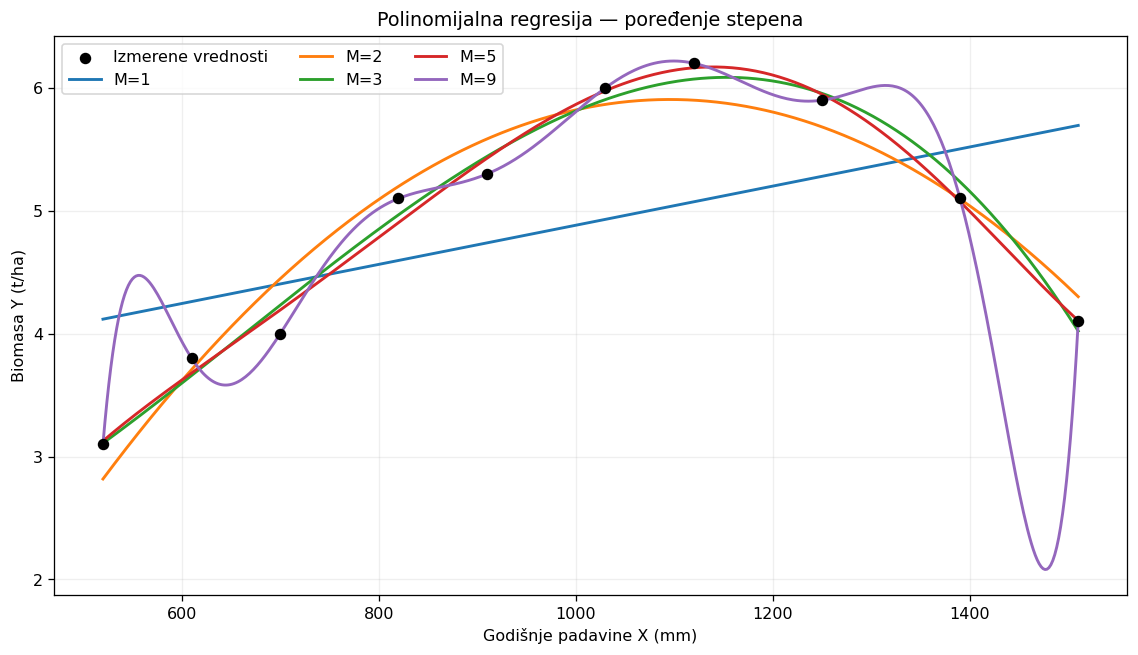

In [4]:
fig, ax = plt.subplots(figsize=(10, 5.8))
x_plot = np.linspace(520, 1510, 500)
ax.scatter(X[:, 0], y, s=38, color='black', zorder=6, label='Izmerene vrednosti')
for M in stepeni:
    ax.plot(x_plot, modeli[M].predict(x_plot), linewidth=1.8, label=f'M={M}')
ax.set(xlabel='Godišnje padavine X (mm)', ylabel='Biomasa Y (t/ha)',
       title='Polinomijalna regresija — poređenje stepena')
ax.grid(alpha=0.2)
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig('rezultati/zadatak_3_modeli.png', dpi=180)
plt.show()

### Grafikon 2 — Ekstrapolacija do 1600 mm

Kriva visokog stepena može savršeno pogoditi obučavajuća merenja, a ipak davati ekstremna predviđanja van njih.

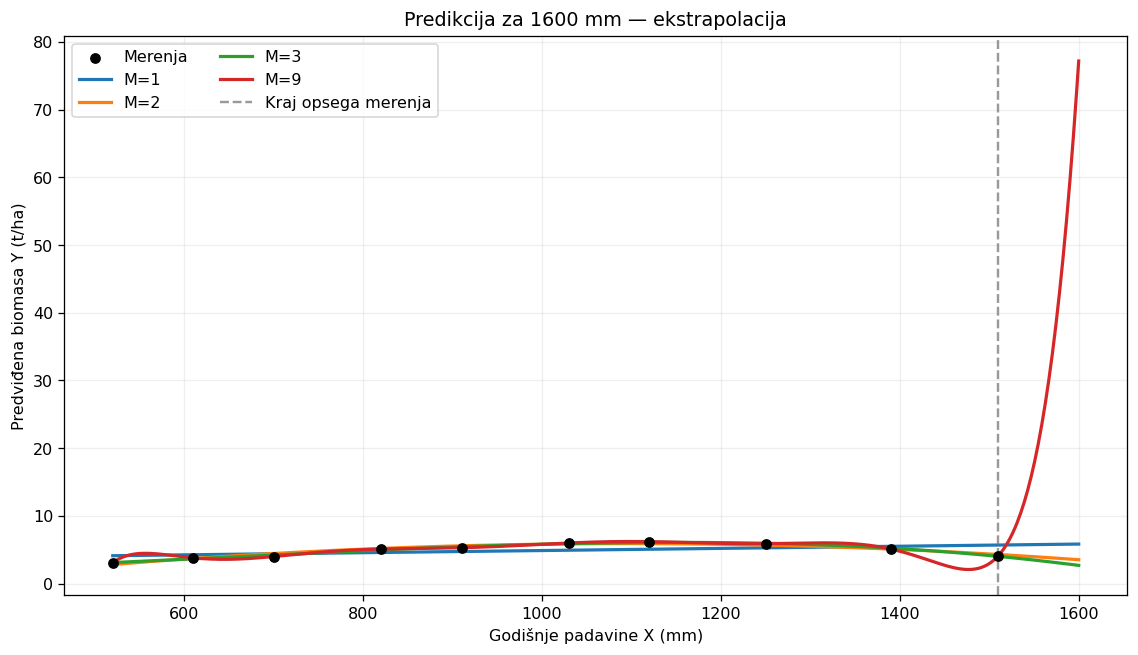

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.8))
x_plot = np.linspace(520, 1600, 550)
ax.scatter(X[:, 0], y, color='black', s=33, zorder=6, label='Merenja')
for M in [1, 2, 3, 9]:
    ax.plot(x_plot, modeli[M].predict(x_plot), linewidth=2, label=f'M={M}')
ax.axvline(1510, linestyle='--', color='grey', alpha=0.8, label='Kraj opsega merenja')
ax.set(xlabel='Godišnje padavine X (mm)', ylabel='Predviđena biomasa Y (t/ha)',
       title='Predikcija za 1600 mm — ekstrapolacija')
ax.legend(ncol=2)
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig('rezultati/zadatak_3_ekstrapolacija.png', dpi=180)
plt.show()

### Grafikon 3 — Greška na skupu za obuku

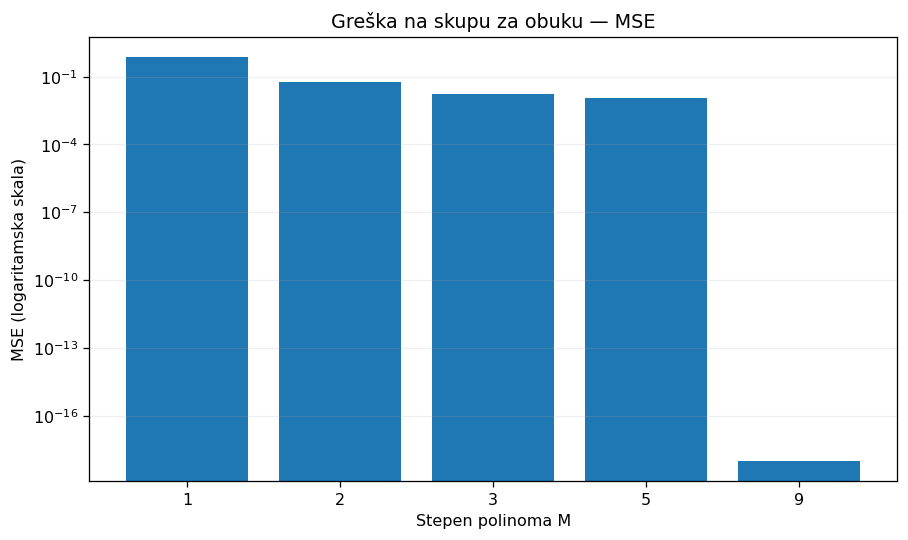

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar([str(M) for M in stepeni], [max(modeli[M].score(X, y), 1e-18) for M in stepeni])
ax.set_yscale('log')
ax.set(xlabel='Stepen polinoma M', ylabel='MSE (logaritamska skala)',
       title='Greška na skupu za obuku — MSE')
ax.grid(axis='y', alpha=0.2)
fig.tight_layout()
fig.savefig('rezultati/zadatak_3_mse.png', dpi=180)
plt.show()

**Napomena za logaritamski grafikon:** za M=9 izračunata MSE je numerički 0; samo za prikaz na logaritamskoj skali koristi se donja granica $10^{-18}$.

## Diskusija: underfitting i overfitting

1. **Nedovoljna prilagođenost (underfitting):** za $M=1$ model je prava. Ne može da opiše porast biomase i kasnije opadanje, zbog čega ima relativno visoku grešku na obuci.
2. **Povećanje stepena:** modeli $M=2$, $M=3$ i $M=5$ sve bolje prate oblik posmatrane veze. MSE na obuci se smanjuje, ali to samo po sebi ne dokazuje bolju generalizaciju.
3. **Preterana prilagođenost (overfitting):** za $M=9$ postoji deset koeficijenata za deset različitih merenja. Matematički takav polinom interpolira tačke (MSE je praktično nula), ali pri ekstrapolaciji za 1600 mm može da daje krajnje nepouzdano predviđanje.
4. **Numerička stabilnost:** pošto su vrednosti X oko 500–1500 mm, visoki stepeni $x^j$ su vrlo veliki. Matrica $\Phi^T\Phi$ je loše uslovljena. Zato je za $M=9$ korišćeno računanje povećanom preciznošću iste formule, bez menjanja ulaznih jedinica.
5. **Ograničenje zaključka:** prikazana MSE meri grešku na skupu za obuku. Bez novih *merenih* vrednosti Y ne možemo izračunati stvarnu grešku generalizacije.

In [7]:
print('MSE za M=1:', f'{modeli[1].score(X, y):.8f}')
print('MSE za M=9:', f'{modeli[9].score(X, y):.8g}')
print('Predikcija M=9 na X=1600 mm:', f'{modeli[9].predict([[1600]])[0]:.6f}')

MSE za M=1: 0.74845297
MSE za M=9: 0
Predikcija M=9 na X=1600 mm: 77.186922
